In [1]:
import pandas as pd
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

In [9]:
ctt_memmap = np.memmap(
    "/work/scratch-nopw2/mendrika/ASNIE/analysis/core_ctt_distribution_JJAS2025_masked.dat",
    dtype="float32",
    mode="r"
)

print("10th percentile (intense deep cloud):", np.percentile(ctt_memmap, 10), flush=True)
print("5th percentile (extreme deep convection):", np.percentile(ctt_memmap, 5), flush=True)
print("2nd percentile (most extreme convection):", np.percentile(ctt_memmap, 2), flush=True)
print("any convection):", np.percentile(ctt_memmap, 100), flush=True)

10th percentile (intense deep cloud): -79.52919006347656
5th percentile (extreme deep convection): -80.74365997314453
2nd percentile (most extreme convection): -82.63975524902344
any convection): -50.023651123046875


In [12]:
def percentile_threshold(hist_path, bins_path, percentile):

    hist = np.loadtxt(hist_path)
    bins = np.loadtxt(bins_path)

    total = np.sum(hist)
    target = percentile * total

    count = 0
    i = 0

    while count < target:
        count += hist[i]
        if count < target:
            i += 1

    p0 = count / total
    p1 = (count - hist[i]) / total

    l0 = np.log(bins[i+1])
    l1 = np.log(bins[i])

    l = ((l0 - l1) / (p0 - p1)) * (percentile - p1) + l1
    threshold = np.exp(l)

    return threshold


hist_file = "/home/users/mendrika/ASNIE/Outputs/mtg-hist.txt"
bins_file = "/home/users/mendrika/ASNIE/Outputs/mtg-bin.txt"

print("LI 90:", percentile_threshold(hist_file, bins_file, 0.90))
print("LI 95:", percentile_threshold(hist_file, bins_file, 0.95))
print("LI 98:", percentile_threshold(hist_file, bins_file, 0.98))

LI 90: 1.0555183037831002
LI 95: 2.6169972316247514
LI 98: 7.062363989624199


In [35]:
BASE = Path("/work/scratch-nopw2/mendrika/ASNIE/database/parquet")

# 90th percentile
df_core_90 = pd.read_parquet(BASE / "core_thr_79p5292.parquet")
df_li_90   = pd.read_parquet(BASE / "li_thr_1p0555.parquet")

# 95th percentile
df_core_95 = pd.read_parquet(BASE / "core_thr_80p7437.parquet")
df_li_95   = pd.read_parquet(BASE / "li_thr_2p6170.parquet")

In [ ]:
def latlon_to_xy_km(lat, lon):
    R = 6371.0
    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)
    x = R * lon_rad * np.cos(np.mean(lat_rad))
    y = R * lat_rad
    return np.column_stack((x, y))


def core_to_li_distances(df_core, df_li):

    time_cols = ["year", "month", "day", "hour"]
    matches = []

    for time_key, core_group in df_core.groupby(time_cols):

        li_group = df_li[
            (df_li["year"]  == time_key[0]) &
            (df_li["month"] == time_key[1]) &
            (df_li["day"]   == time_key[2]) &
            (df_li["hour"]  == time_key[3])
        ]

        if len(core_group) == 0 or len(li_group) == 0:
            continue

        li_xy = latlon_to_xy_km(
            li_group["lat_centroid"].values,
            li_group["lon_centroid"].values
        )

        tree = cKDTree(li_xy)

        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        distances, _ = tree.query(core_xy, k=1)
        matches.extend(distances)

    return np.array(matches)


In [37]:
matches_90 = core_to_li_distances(df_core_90, df_li_90)
matches_95 = core_to_li_distances(df_core_95, df_li_95)

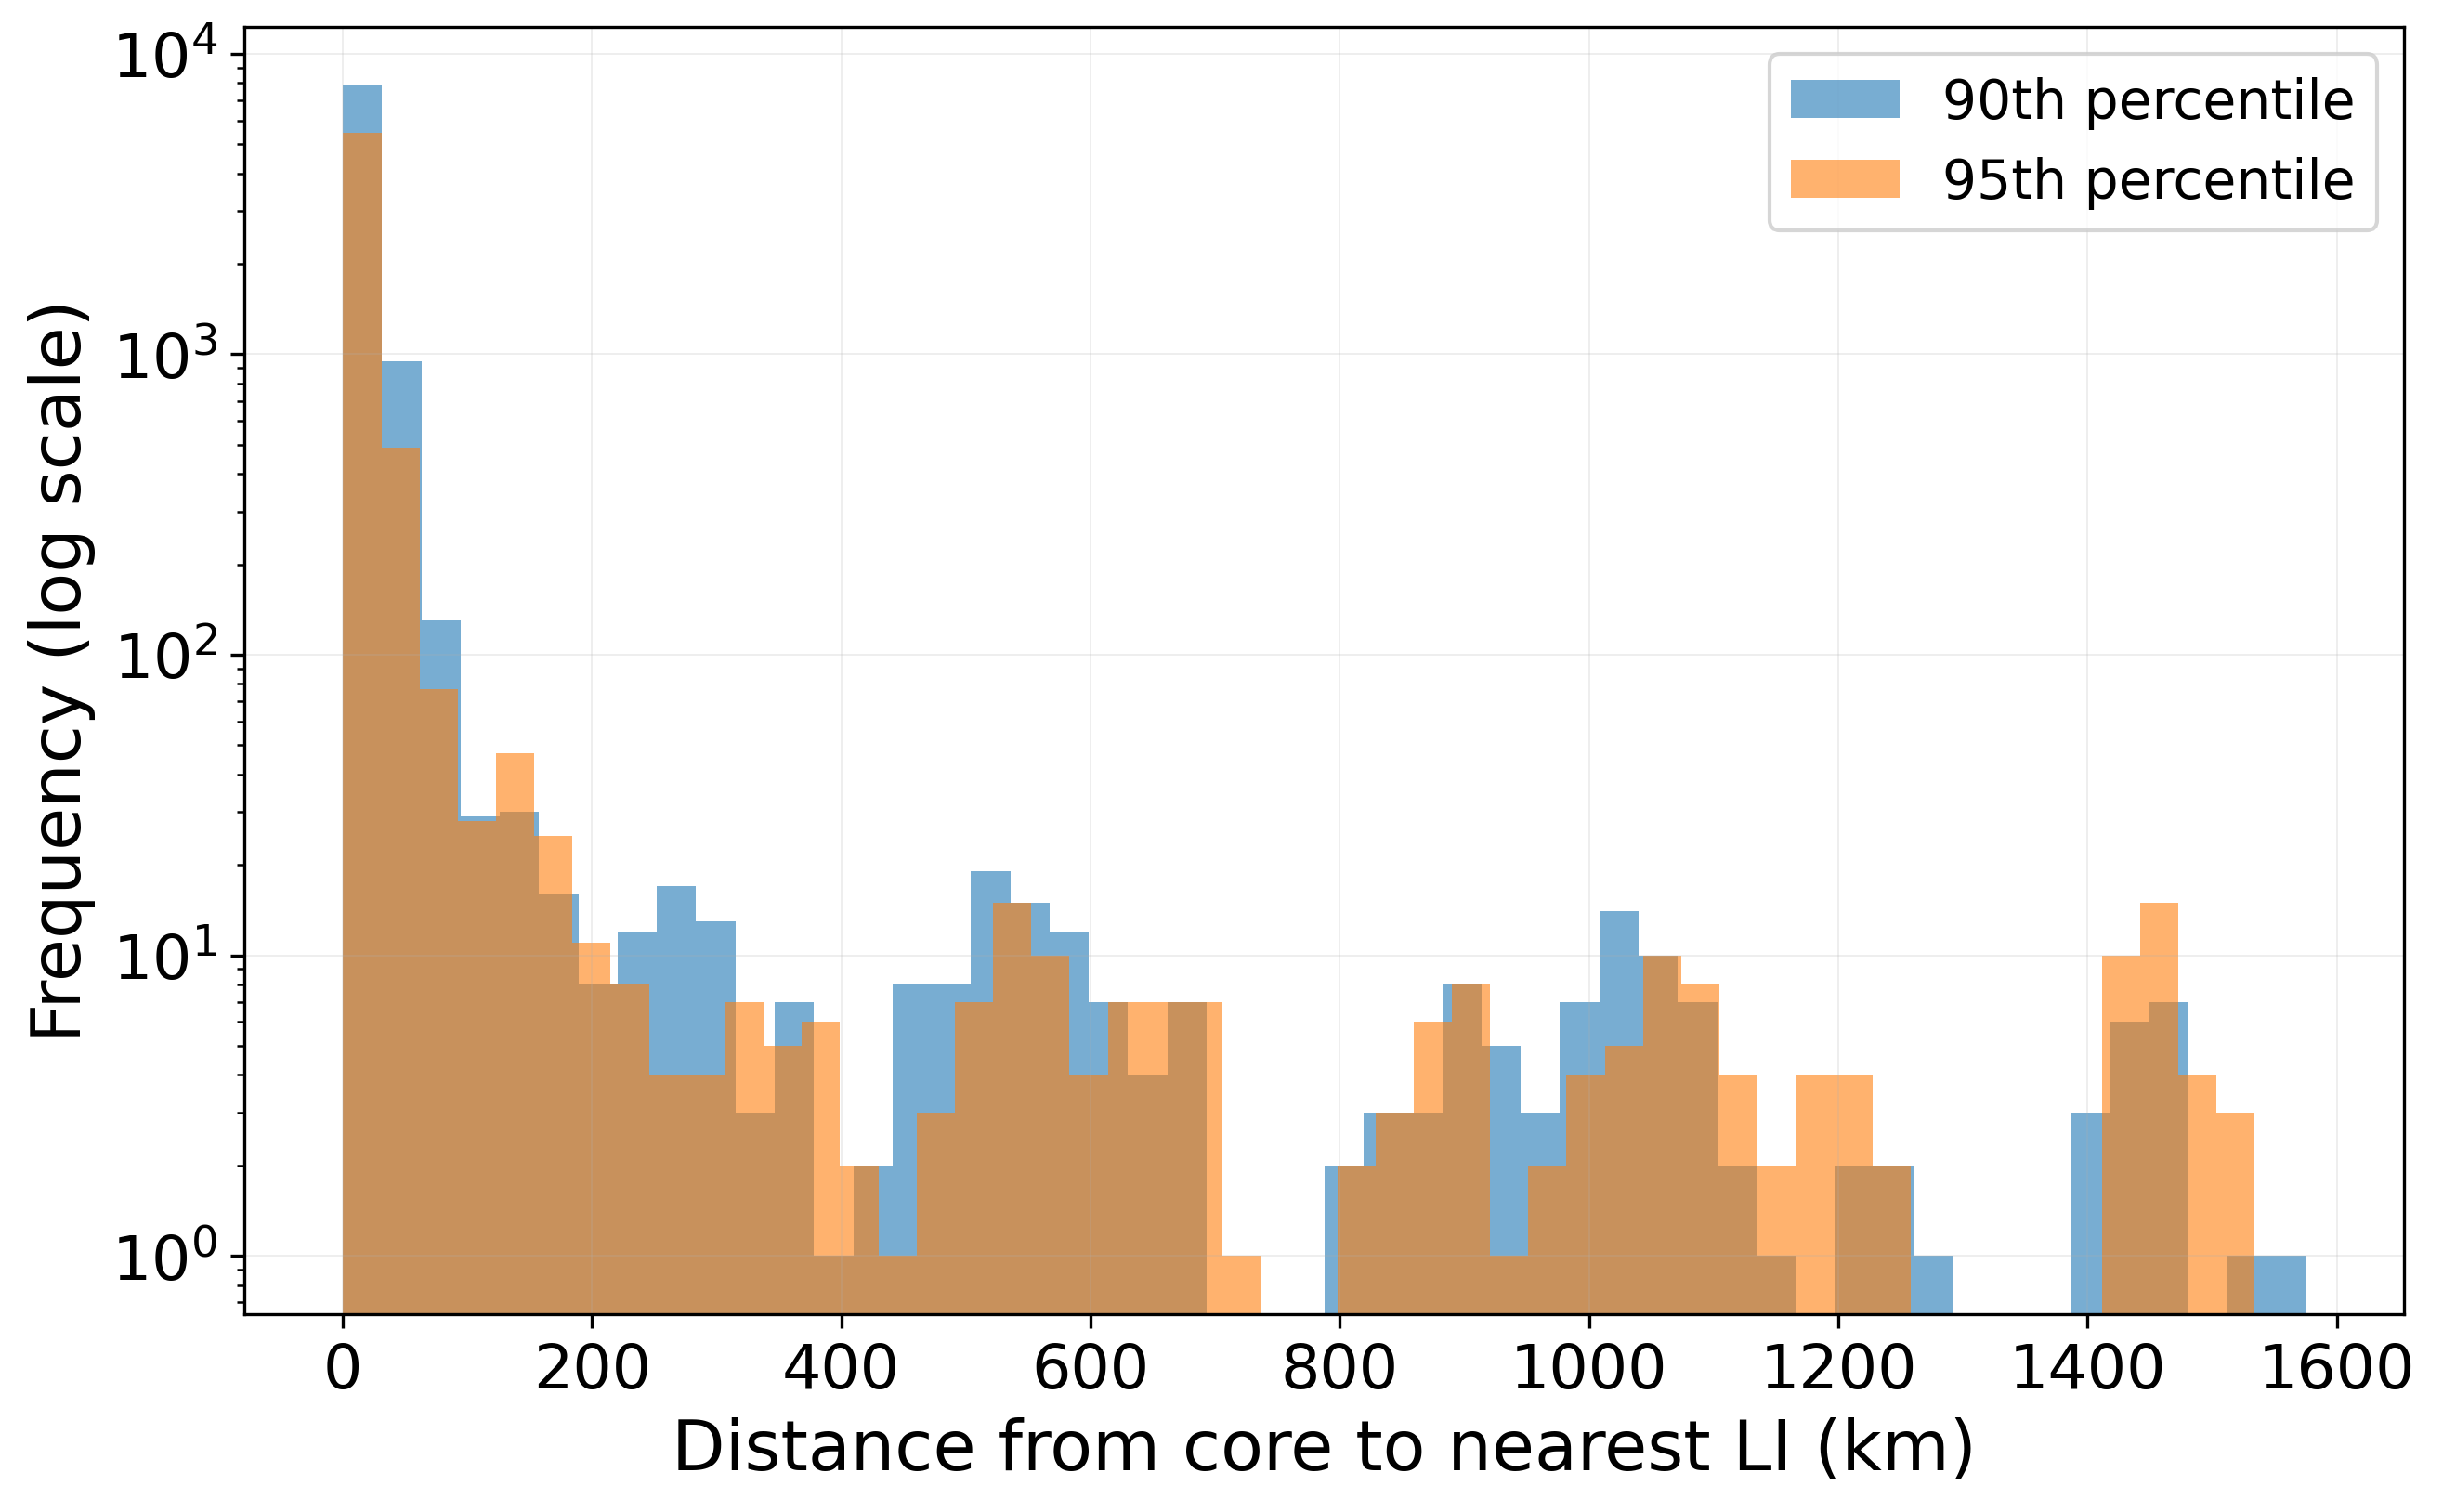

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6), dpi=300)

plt.hist(matches_90, bins=50, alpha=0.6, label="90th percentile")
plt.hist(matches_95, bins=50, alpha=0.6, label="95th percentile")

plt.yscale("log")

plt.xlabel("Distance from core to nearest LI (km)", fontsize=18)
plt.ylabel("Frequency (log scale)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()

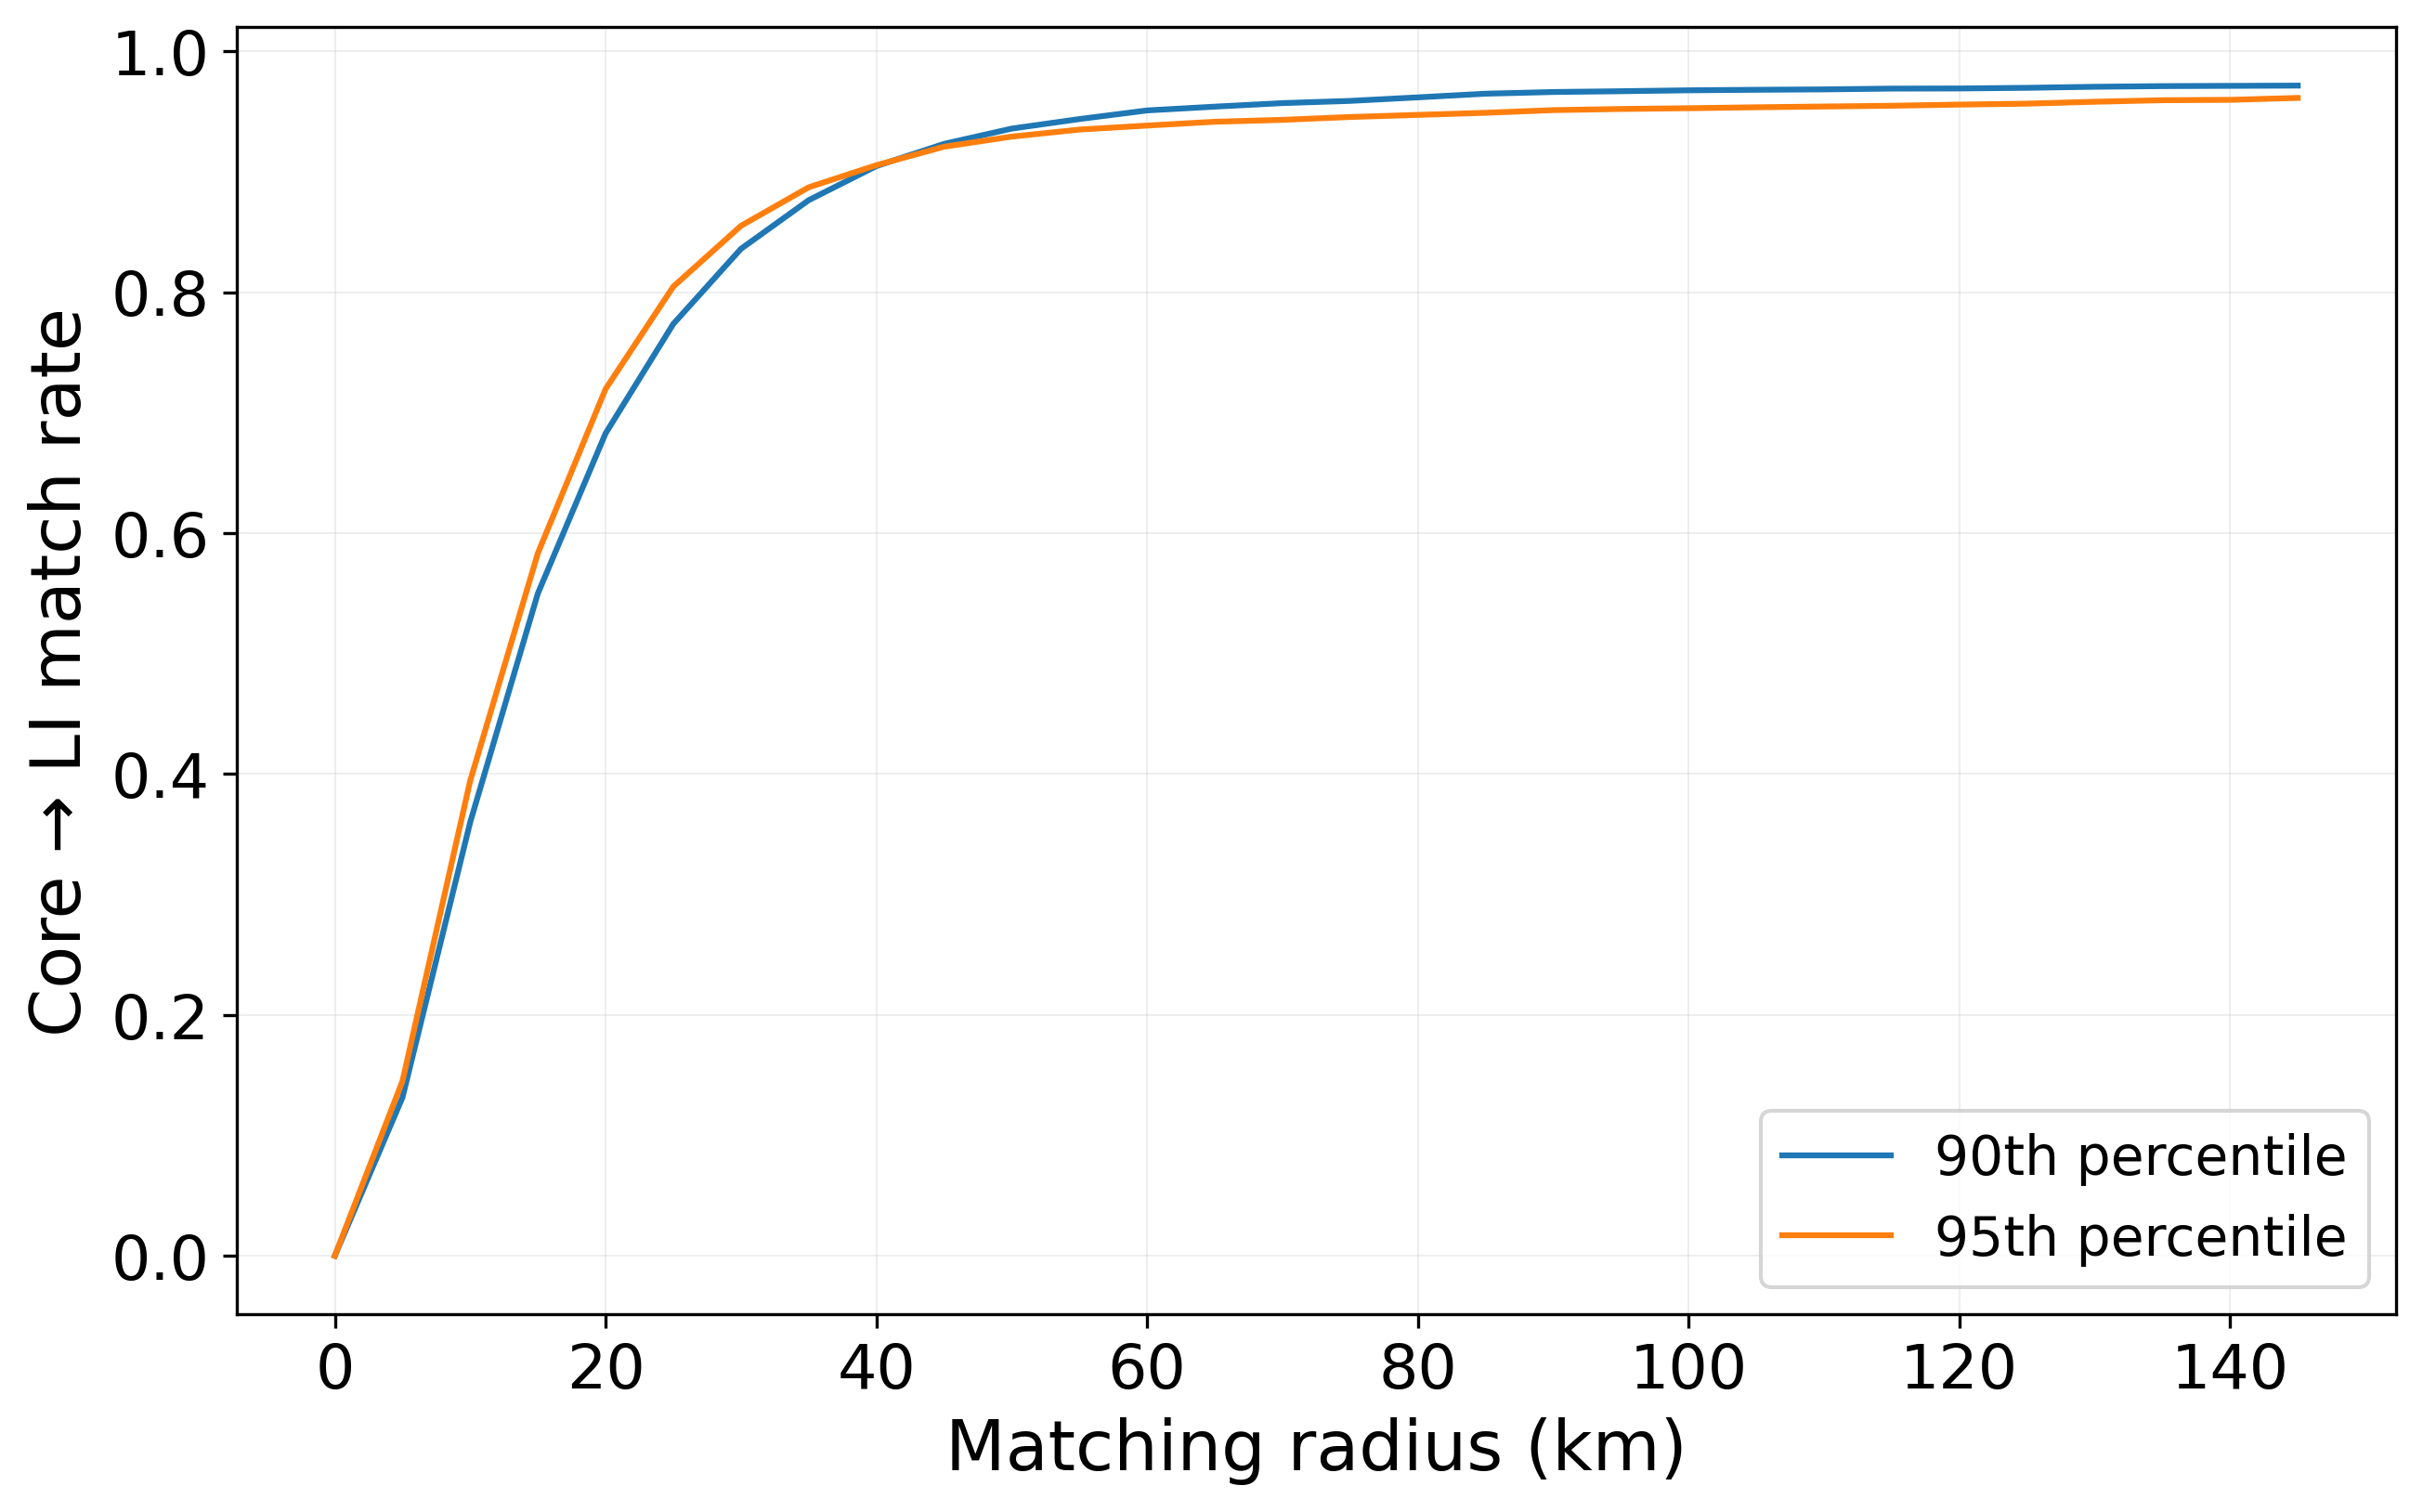

In [39]:
radii = np.arange(0, 150, 5)

rates_90 = [np.mean(matches_90 <= r) for r in radii]
rates_95 = [np.mean(matches_95 <= r) for r in radii]

plt.figure(figsize=(10, 6), dpi=300)

plt.plot(radii, rates_90, label="90th percentile")
plt.plot(radii, rates_95, label="95th percentile")

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Core → LI match rate", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()


In [40]:
print("50 km match rate (90):", np.mean(matches_90 <= 50))
print("50 km match rate (95):", np.mean(matches_95 <= 50))

50 km match rate (90): 0.9357638888888888
50 km match rate (95): 0.9291027061243867


In [41]:
import numpy as np
from scipy.spatial import cKDTree

def latlon_to_xy_km(lat, lon):
    R = 6371.0
    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)
    x = R * lon_rad * np.cos(np.mean(lat_rad))
    y = R * lat_rad
    return np.column_stack((x, y))


def li_to_core_distances(df_core, df_li):

    time_cols = ["year", "month", "day", "hour"]
    matches = []

    for time_key, li_group in df_li.groupby(time_cols):

        core_group = df_core[
            (df_core["year"]  == time_key[0]) &
            (df_core["month"] == time_key[1]) &
            (df_core["day"]   == time_key[2]) &
            (df_core["hour"]  == time_key[3])
        ]

        if len(li_group) == 0 or len(core_group) == 0:
            continue

        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        tree = cKDTree(core_xy)

        li_xy = latlon_to_xy_km(
            li_group["lat_centroid"].values,
            li_group["lon_centroid"].values
        )

        distances, _ = tree.query(li_xy, k=1)
        matches.extend(distances)

    return np.array(matches)

In [47]:
li_core_90 = li_to_core_distances(df_core_90, df_li_90)

print("Total matched LI objects:", len(li_core_90))
print("Mean distance (km):", np.mean(li_core_90))
print("Median distance (km):", np.median(li_core_90))
print("Match rate within 25 km:", np.mean(li_core_90 <= 25))
print("Match rate within 50 km:", np.mean(li_core_90 <= 50))
print("Match rate within 100 km:", np.mean(li_core_90 <= 100))

li_core_95 = li_to_core_distances(df_core_95, df_li_95)

print("Total matched LI objects (95):", len(li_core_95))
print("Mean distance (km):", np.mean(li_core_95))
print("Median distance (km):", np.median(li_core_95))
print("Match rate within 25 km:", np.mean(li_core_95 <= 25))
print("Match rate within 50 km:", np.mean(li_core_95 <= 50))
print("Match rate within 100 km:", np.mean(li_core_95 <= 100))

Total matched LI objects: 76620
Mean distance (km): 318.83660300504044
Median distance (km): 213.49920692370586
Match rate within 25 km: 0.12748629600626468
Match rate within 50 km: 0.2116940746541373
Match rate within 100 km: 0.3354998694857739
Total matched LI objects (95): 44189
Mean distance (km): 300.328693280974
Median distance (km): 185.11586786840363
Match rate within 25 km: 0.15798049288284416
Match rate within 50 km: 0.2513521464617891
Match rate within 100 km: 0.3728529724592093


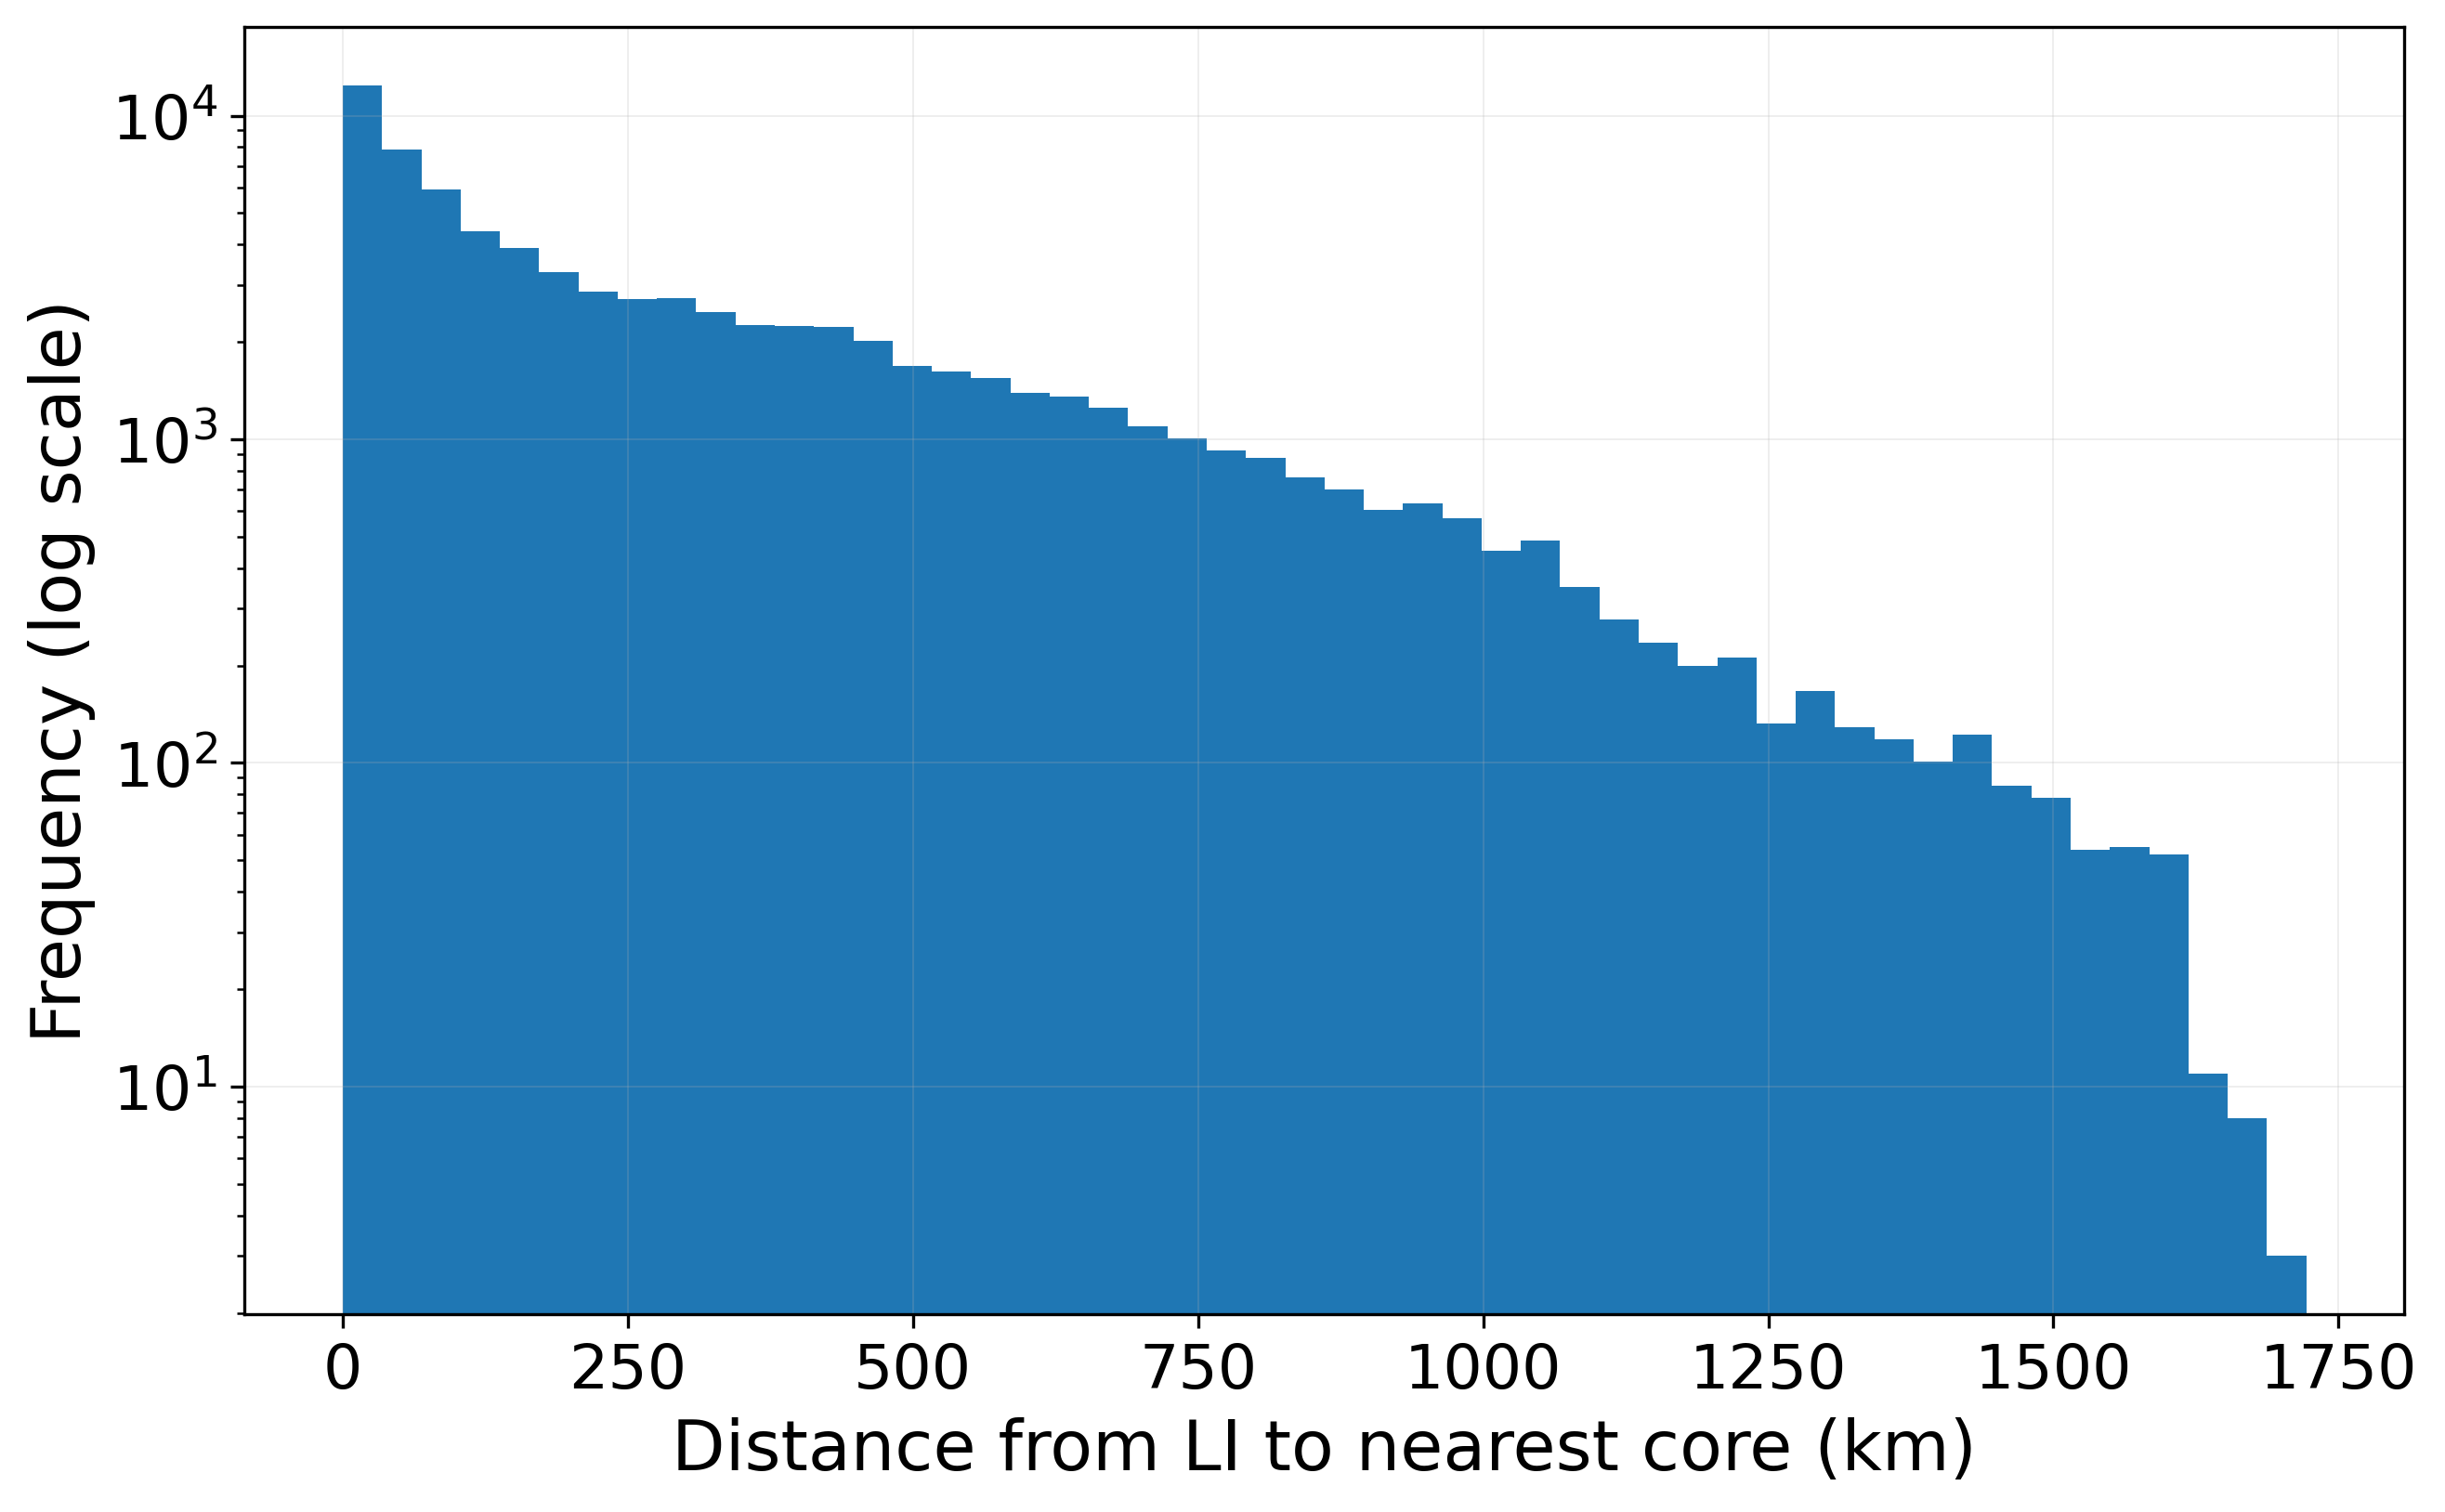

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6), dpi=300)

plt.hist(li_core_90, bins=50)
plt.yscale("log")

plt.xlabel("Distance from LI to nearest core (km)", fontsize=18)
plt.ylabel("Frequency (log scale)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, linewidth=0.1)

plt.show()

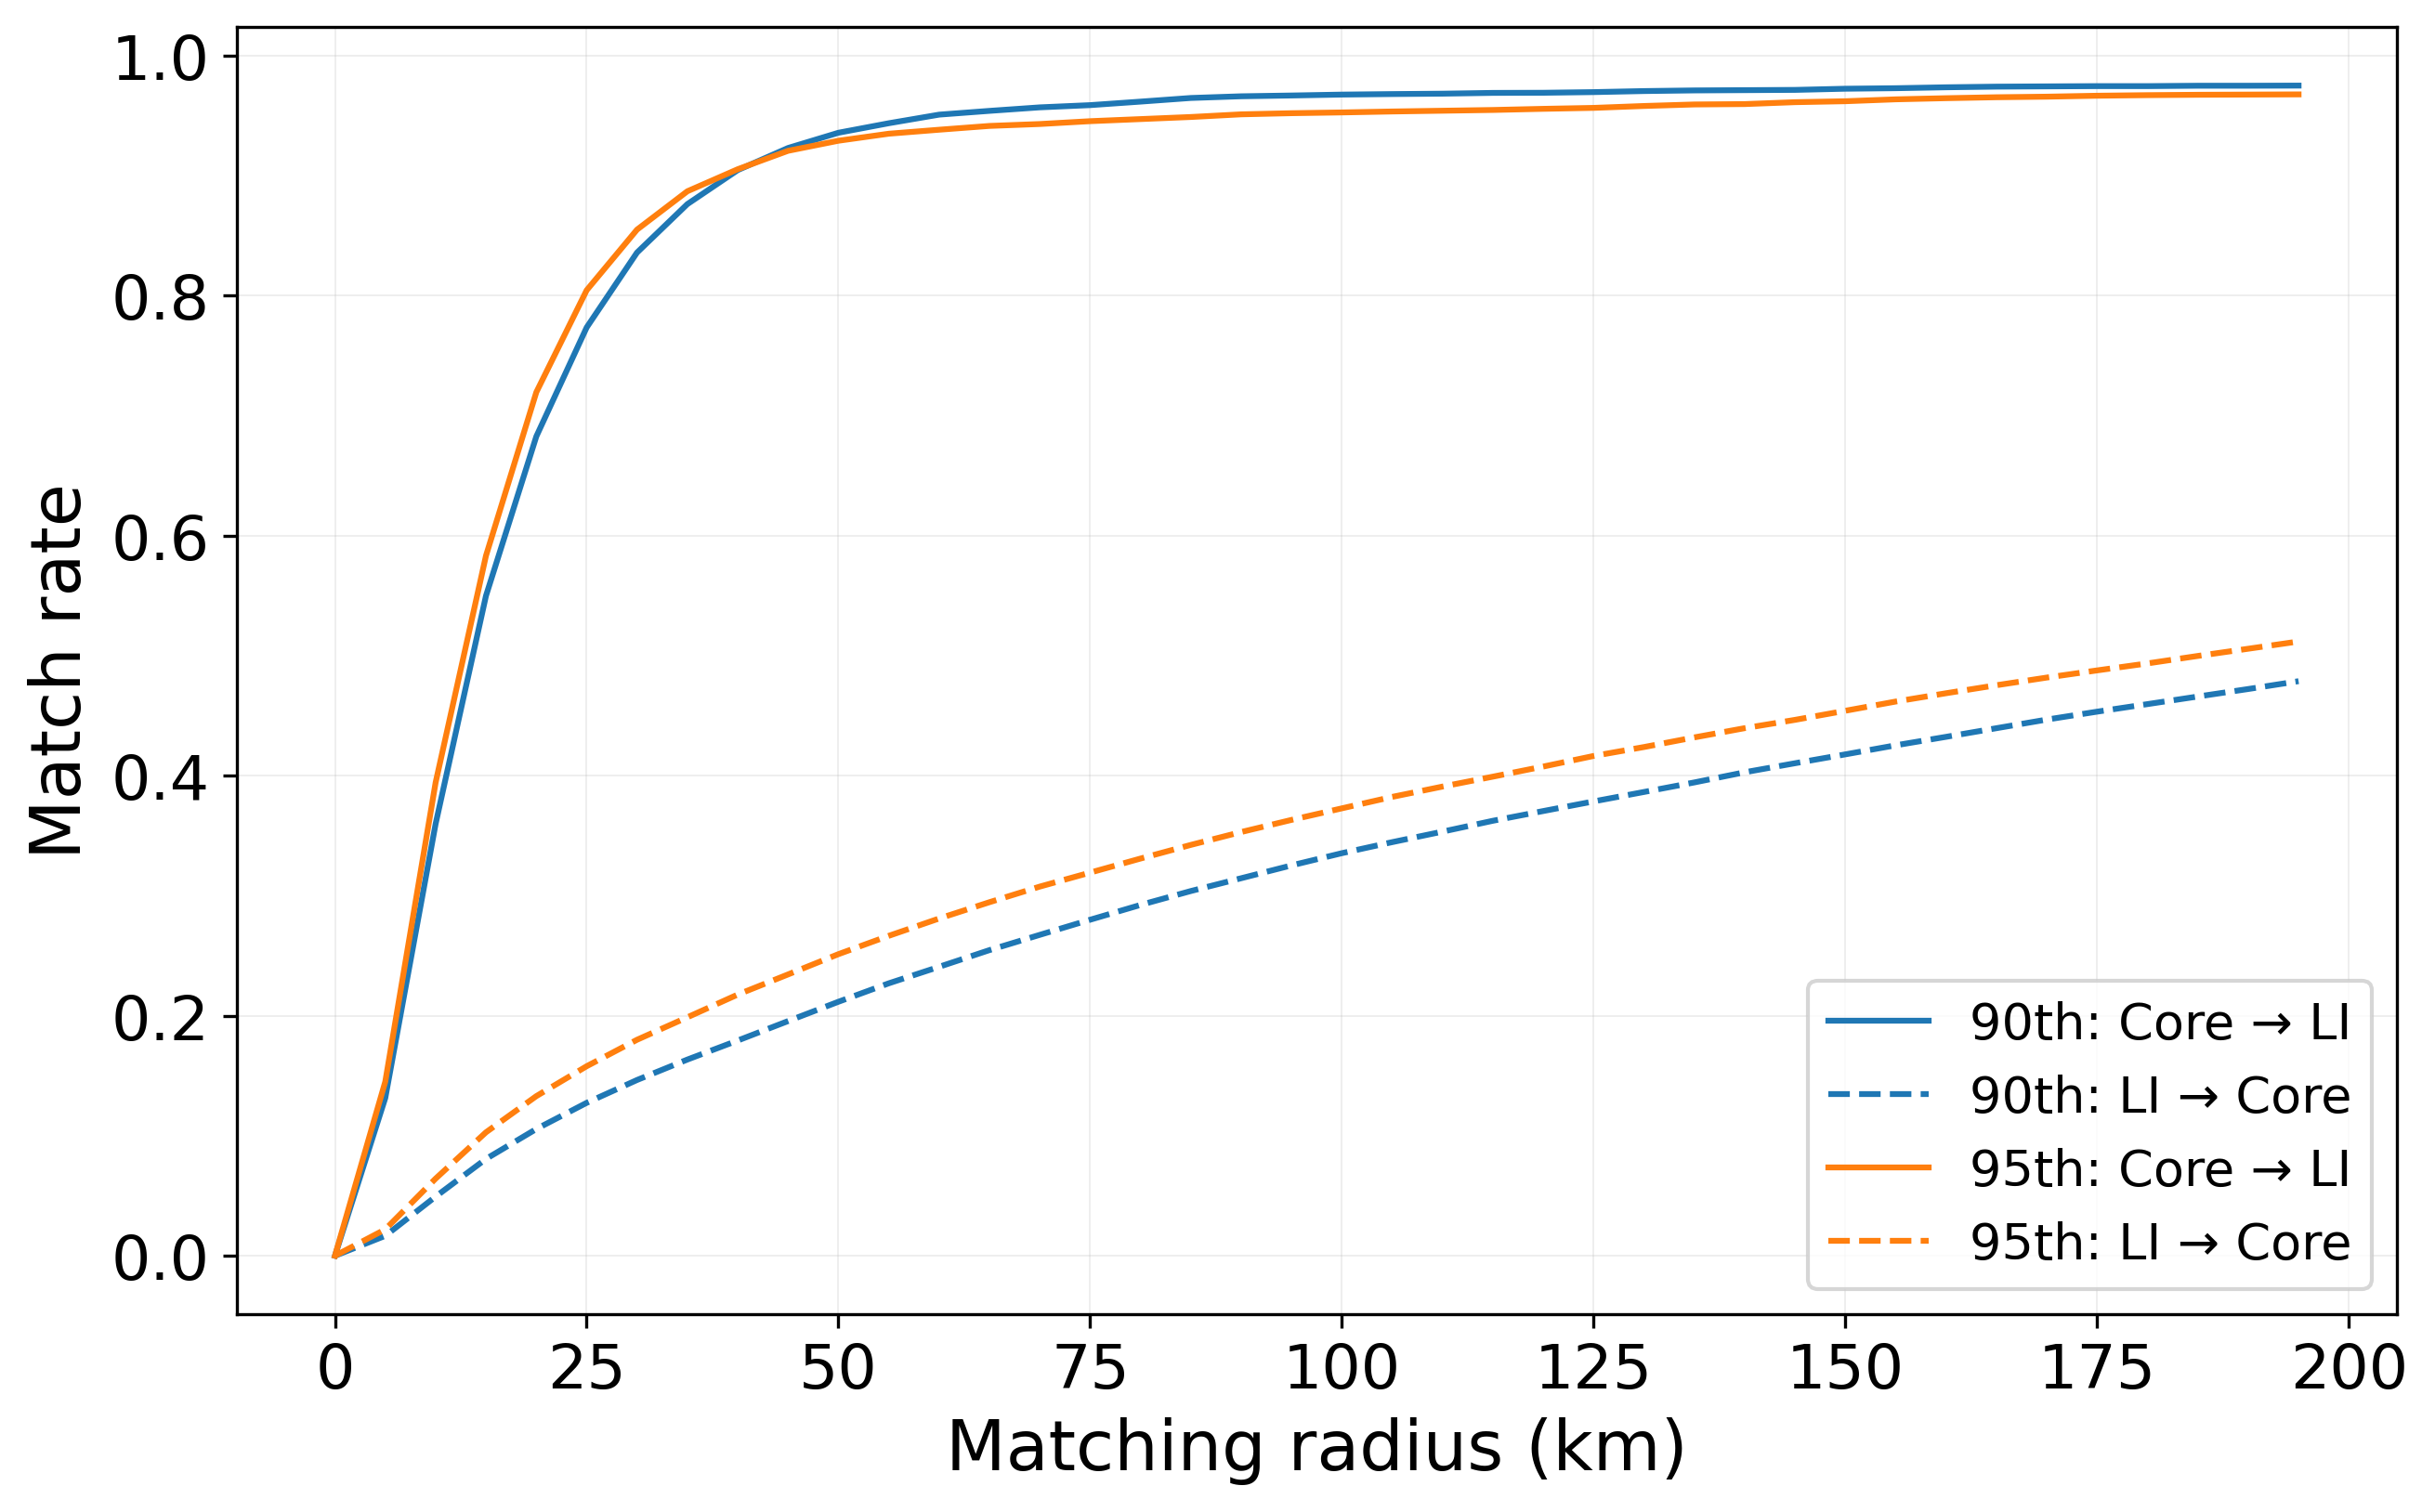

In [54]:
plt.figure(figsize=(10, 6), dpi=300)

blue = "#1f77b4"
orange = "#ff7f0e"

# 90th percentile
plt.plot(radii, rates_c_li_90, color=blue, linestyle="-",  label="90th: Core → LI")
plt.plot(radii, rates_li_c_90, color=blue, linestyle="--", label="90th: LI → Core")

# 95th percentile
plt.plot(radii, rates_c_li_95, color=orange, linestyle="-",  label="95th: Core → LI")
plt.plot(radii, rates_li_c_95, color=orange, linestyle="--", label="95th: LI → Core")

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Match rate", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=13)
plt.grid(True, linewidth=0.1)

plt.show()
